## Google Play Store Dataset Analysis

**Dataset:** Google Play Store Apps  
**Source:** [Kaggle](https://www.kaggle.com/datasets/lava18/google-play-store-apps)  
**File:** `googleplaystore.csv`

#### Problem statement
Analyze Google Play Store applications to understand app categories, ratings, installations, reviews, pricing, and other characteristics. Clean and preprocess the data, explore patterns, create visualizations, and engineer useful features.

#### Objectives
1. Explore the dataset using NumPy and Pandas.
2. Clean missing, duplicate, inconsistent, and incorrectly typed data.
3. Perform exploratory data analysis (EDA).
4. Create static and interactive visualizations.
5. Engineer useful features, encode categories, and scale numerical variables.
6. Summarize findings, limitations, and recommendations.

#### Python and NumPy

Import the required libraries, load numerical columns into NumPy arrays, and demonstrate array creation, indexing, slicing, arithmetic, and descriptive statistics.

In [3]:
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from IPython.display import display

DATA_DIR = Path.cwd()

#### Step 1 – Dataset Collection

In [6]:
DATA_PATH = DATA_DIR / "./GooglePlayStoreDataset.csv"

df_original = pd.read_csv(DATA_PATH)
df = df_raw.copy()

print("Dataset loaded.")
print("Shape:", df.shape)
display(df.head())

Dataset loaded.
Shape: (10841, 13)


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


In [7]:
# Convert suitable columns to NumPy arrays.
rating_array = pd.to_numeric(df_original["Rating"], errors="coerce").dropna().to_numpy()
reviews_array = pd.to_numeric(df_original["Reviews"], errors="coerce").dropna().to_numpy()

print("First 10 ratings:", rating_array[:10])
print("First 10 review counts:", reviews_array[:10])

First 10 ratings: [4.1 3.9 4.7 4.5 4.3 4.4 3.8 4.1 4.4 4.7]
First 10 review counts: [1.59000e+02 9.67000e+02 8.75100e+04 2.15644e+05 9.67000e+02 1.67000e+02
 1.78000e+02 3.68150e+04 1.37910e+04 1.21000e+02]


In [8]:
# Array creation, indexing, slicing, and arithmetic
sample_array = np.array([10, 20, 30, 40, 50])

print("Array:", sample_array)
print("First element:", sample_array[0])
print("Third element:", sample_array[2])
print("First three elements:", sample_array[:3])
print("Last two elements:", sample_array[-2:])
print("Add 5:", sample_array + 5)
print("Subtract 5:", sample_array - 5)
print("Multiply by 2:", sample_array * 2)
print("Divide by 2:", sample_array / 2)
print("Square:", np.square(sample_array))
print("Square root:", np.sqrt(sample_array))

Array: [10 20 30 40 50]
First element: 10
Third element: 30
First three elements: [10 20 30]
Last two elements: [40 50]
Add 5: [15 25 35 45 55]
Subtract 5: [ 5 15 25 35 45]
Multiply by 2: [ 20  40  60  80 100]
Divide by 2: [ 5. 10. 15. 20. 25.]
Square: [ 100  400  900 1600 2500]
Square root: [3.16227766 4.47213595 5.47722558 6.32455532 7.07106781]


In [9]:
# NumPy descriptive statistics
print("Mean rating:", np.mean(rating_array))
print("Median rating:", np.median(rating_array))
print("Standard deviation:", np.std(rating_array))
print("Minimum rating:", np.min(rating_array))
print("Maximum rating:", np.max(rating_array))
print("25th percentile:", np.percentile(rating_array, 25))
print("50th percentile:", np.percentile(rating_array, 50))
print("75th percentile:", np.percentile(rating_array, 75))

Mean rating: 4.193338315362443
Median rating: 4.3
Standard deviation: 0.537402614899245
Minimum rating: 1.0
Maximum rating: 19.0
25th percentile: 4.0
50th percentile: 4.3
75th percentile: 4.5


#### Pandas Operations

Inspect the first and last records, dimensions, column names, data types, summary statistics, missing values, and duplicates.

In [10]:
print("First five records:")
display(df_original.head())

print("Last five records:")
display(df_original.tail())

print("Rows:", df_original.shape[0])
print("Columns:", df_original.shape[1])
print("Column names:", df_original.columns.tolist())

print("\nData types:")
display(df_original.dtypes.to_frame("Data Type"))

print("\nDataset information:")
df_original.info()

First five records:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


Last five records:


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1.0,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1.0,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature 17+,Books & Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


Rows: 10841
Columns: 13
Column names: ['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type', 'Price', 'Content Rating', 'Genres', 'Last Updated', 'Current Ver', 'Android Ver']

Data types:


,Data Type
App,object
Category,object
Rating,float64
Reviews,object
Size,object
Installs,object
Type,object
Price,object
Content Rating,object
Genres,object



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [11]:
print("Numerical summary:")
display(df_original.describe())

print("Categorical summary:")
display(df_original.describe(include="object"))

print("Missing values by column:")
display(df_original.isna().sum().to_frame("Missing Values"))

print("Total missing values:", int(df_original.isna().sum().sum()))
print("Exact duplicate rows:", int(df_original.duplicated().sum()))
display(df_original[df_original.duplicated()].head())

Numerical summary:


,Rating
count,9367.000000
mean,4.193338
std,0.537431
min,1.000000
25%,4.000000
50%,4.300000
75%,4.500000
max,19.000000


Categorical summary:


,App,Category,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
count,10841,10841,10841,10841,10841,10840,10841,10840,10841,10841,10833,10838
unique,9660,34,6002,462,22,3,93,6,120,1378,2832,33
top,ROBLOX,FAMILY,0,Varies with device,"1,000,000+",Free,0,Everyone,Tools,"August 3, 2018",Varies with device,4.1 and up
freq,9,1972,596,1695,1579,10039,10040,8714,842,326,1459,2451


Missing values by column:


,Missing Values
App,0
Category,0
Rating,1474
Reviews,0
Size,0
Installs,0
Type,1
Price,0
Content Rating,1
Genres,0


Total missing values: 1487
Exact duplicate rows: 483


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
229,Quick PDF Scanner + OCR FREE,BUSINESS,4.2,80805,Varies with device,"5,000,000+",Free,0,Everyone,Business,"February 26, 2018",Varies with device,4.0.3 and up
236,Box,BUSINESS,4.2,159872,Varies with device,"10,000,000+",Free,0,Everyone,Business,"July 31, 2018",Varies with device,Varies with device
239,Google My Business,BUSINESS,4.4,70991,Varies with device,"5,000,000+",Free,0,Everyone,Business,"July 24, 2018",2.19.0.204537701,4.4 and up
256,ZOOM Cloud Meetings,BUSINESS,4.4,31614,37M,"10,000,000+",Free,0,Everyone,Business,"July 20, 2018",4.1.28165.0716,4.0 and up
261,join.me - Simple Meetings,BUSINESS,4.0,6989,Varies with device,"1,000,000+",Free,0,Everyone,Business,"July 16, 2018",4.3.0.508,4.4 and up


#### Data Cleaning and Preprocessing

Work on a copy so the original dataset remains unchanged. Standardize column names, remove malformed rows and exact duplicates, convert data types, fill missing values, and inspect outliers.

In [13]:
df_clean = df_original.copy()

# Standardize column names.
df_clean.columns = (
    df_clean.columns.str.strip().str.lower().str.replace(" ", "_", regex=False)
)

# Remove surrounding whitespace from text columns
for col in df_clean.select_dtypes(include="object").columns:
    df_clean[col] = df_clean[col].str.strip()

print("Shape before cleaning:", df_clean.shape)
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

Shape before cleaning: (10841, 13)
Duplicate rows before cleaning: 483


In [14]:
valid_category = df_clean["category"].str.fullmatch(r"[A-Z_]+", na=False)
invalid_rows = int((~valid_category).sum())
print("Malformed category rows:", invalid_rows)

df_clean = df_clean.loc[valid_category].copy()

# Remove exact duplicate rows.
df_clean = df_clean.drop_duplicates().copy()

print("Shape after removing malformed and duplicate rows:", df_clean.shape)
print("Remaining exact duplicates:", df_clean.duplicated().sum())

Malformed category rows: 1
Shape after removing malformed and duplicate rows: (10357, 13)
Remaining exact duplicates: 0


In [15]:
# Convert Reviews to numeric.
df_clean["reviews"] = pd.to_numeric(df_clean["reviews"], errors="coerce")

# Convert Installs: remove commas and plus signs.
df_clean["installs_numeric"] = (
    df_clean["installs"].astype(str)
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False)
)
df_clean["installs_numeric"] = pd.to_numeric(
    df_clean["installs_numeric"], errors="coerce"
)

# Convert Price: remove dollar sign.
df_clean["price"] = pd.to_numeric(
    df_clean["price"].astype(str).str.replace("$", "", regex=False),
    errors="coerce"
)

# Convert app size to MB. "Varies with device" becomes missing.
def convert_size_to_mb(value):
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value == "Varies with device":
        return np.nan
    try:
        if value.endswith("M"):
            return float(value[:-1])
        if value.endswith("k"):
            return float(value[:-1]) / 1024
    except ValueError:
        return np.nan
    return np.nan

df_clean["size_mb"] = df_clean["size"].apply(convert_size_to_mb)

# Convert date column.
df_clean["last_updated"] = pd.to_datetime(
    df_clean["last_updated"], errors="coerce"
)

print(df_clean[["reviews", "installs_numeric", "price", "size_mb", "last_updated"]].dtypes)
display(df_clean[["reviews", "installs_numeric", "price", "size_mb", "last_updated"]].head())

reviews                      int64
installs_numeric             int64
price                      float64
size_mb                    float64
last_updated        datetime64[ns]
dtype: object


,reviews,installs_numeric,price,size_mb,last_updated
0,159,10000,0.0,19.0,2018-01-07
1,967,500000,0.0,14.0,2018-01-15
2,87510,5000000,0.0,8.7,2018-08-01
3,215644,50000000,0.0,25.0,2018-06-08
4,967,100000,0.0,2.8,2018-06-20


In [16]:
# Handle missing values.
# Fill rating with the median rating within its app category.
df_clean["rating"] = pd.to_numeric(df_clean["rating"], errors="coerce")
df_clean["rating"] = df_clean.groupby("category")["rating"].transform(
    lambda series: series.fillna(series.median())
)
df_clean["rating"] = df_clean["rating"].fillna(df_clean["rating"].median())

# Fill numerical columns with their medians.
for col in ["reviews", "installs_numeric", "price", "size_mb"]:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill categorical columns with their mode.
categorical_fill_cols = [
    "type", "content_rating", "current_ver", "android_ver"
]
for col in categorical_fill_cols:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode(dropna=True)
        fill_value = mode_values.iloc[0] if not mode_values.empty else "Unknown"
        df_clean[col] = df_clean[col].fillna(fill_value)

print("Missing values after imputation:")
display(df_clean.isna().sum().to_frame("Missing Values"))

Missing values after imputation:


,Missing Values
app,0
category,0
rating,0
reviews,0
size,0
installs,0
type,0
price,0
content_rating,0
genres,0


In [17]:
# Detect outliers using the IQR method. Outliers are reported, not automatically deleted.
numerical_cols = ["rating", "reviews", "installs_numeric", "price", "size_mb"]

outlier_summary = []
for col in numerical_cols:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = int(((df_clean[col] < lower) | (df_clean[col] > upper)).sum())
    outlier_summary.append({
        "Column": col, "Lower Bound": lower,
        "Upper Bound": upper, "Outlier Count": count
    })

display(pd.DataFrame(outlier_summary))

,Column,Lower Bound,Upper Bound,Outlier Count
0,rating,3.50,5.10,723
1,reviews,-69544.00,115992.00,1870
2,installs_numeric,-1497500.00,2498500.00,2566
3,price,0.00,0.00,765
4,size_mb,-24.75,56.45,831


In [18]:
# Compare original and cleaned data.
comparison = pd.DataFrame({
    "Before Cleaning": [
        len(df_original),
        df_original.shape[1],
        int(df_original.isna().sum().sum()),
        int(df_original.duplicated().sum())
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        int(df_clean.isna().sum().sum()),
        int(df_clean.duplicated().sum())
    ]
}, index=["Rows", "Columns", "Missing cells", "Duplicate rows"])

display(comparison)

,Before Cleaning,After Cleaning
Rows,10841,10357
Columns,13,15
Missing cells,1487,0
Duplicate rows,483,0


#### Exploratory Data Analysis (EDA)

Calculate descriptive statistics and analyze numerical and categorical variables, app categories, free versus paid apps, and correlations.

In [19]:
# Descriptive statistics for cleaned numerical data.
display(df_clean[["rating", "reviews", "installs_numeric", "price", "size_mb"]].describe())

# Numerical variable summaries.
for col in ["rating", "reviews", "installs_numeric", "price", "size_mb"]:
    print(
        f"{col}: mean={df_clean[col].mean():.2f}, "
        f"median={df_clean[col].median():.2f}, "
        f"std={df_clean[col].std():.2f}, "
        f"min={df_clean[col].min():.2f}, "
        f"max={df_clean[col].max():.2f}"
    )

,rating,reviews,installs_numeric,price,size_mb
count,10357.000000,1.035700e+04,1.035700e+04,10357.000000,10357.000000
mean,4.202332,4.059046e+05,1.415776e+07,1.030800,20.066346
std,0.486371,2.696778e+06,8.023955e+07,16.278625,21.019993
min,1.000000,0.000000e+00,0.000000e+00,0.000000,0.008301
25%,4.100000,3.200000e+01,1.000000e+03,0.000000,5.700000
50%,4.300000,1.680000e+03,1.000000e+05,0.000000,13.000000
75%,4.500000,4.641600e+04,1.000000e+06,0.000000,26.000000
max,5.000000,7.815831e+07,1.000000e+09,400.000000,100.000000


rating: mean=4.20, median=4.30, std=0.49, min=1.00, max=5.00
reviews: mean=405904.61, median=1680.00, std=2696777.84, min=0.00, max=78158306.00
installs_numeric: mean=14157759.44, median=100000.00, std=80239553.87, min=0.00, max=1000000000.00
price: mean=1.03, median=0.00, std=16.28, min=0.00, max=400.00
size_mb: mean=20.07, median=13.00, std=21.02, min=0.01, max=100.00


In [20]:
print("Apps by category:")
display(df_clean["category"].value_counts().to_frame("App Count"))

print("Free and paid apps:")
display(df_clean["type"].value_counts().to_frame("App Count"))

print("Content rating distribution:")
display(df_clean["content_rating"].value_counts().to_frame("App Count"))

print("Top 10 genres:")
display(df_clean["genres"].value_counts().head(10).to_frame("App Count"))

Apps by category:


,App Count
category,
FAMILY,1943
GAME,1121
TOOLS,843
BUSINESS,427
MEDICAL,408
PRODUCTIVITY,407
PERSONALIZATION,388
LIFESTYLE,373
COMMUNICATION,366


Free and paid apps:


,App Count
type,
Free,9592
Paid,765


Content rating distribution:


,App Count
content_rating,
Everyone,8382
Teen,1146
Mature 17+,447
Everyone 10+,377
Adults only 18+,3
Unrated,2


Top 10 genres:


,App Count
genres,
Tools,842
Entertainment,588
Education,527
Business,427
Medical,408
Productivity,407
Personalization,388
Lifestyle,372
Communication,366


In [21]:
# Category-level analysis.
category_analysis = (
    df_clean.groupby("category")
    .agg(
        total_apps=("app", "count"),
        average_rating=("rating", "mean"),
        total_installs=("installs_numeric", "sum"),
        average_reviews=("reviews", "mean")
    )
    .sort_values("total_installs", ascending=False)
)
display(category_analysis.head(10))

,total_apps,average_rating,total_installs,average_reviews
category,,,,
GAME,1121,4.282070,31544024415,1.262745e+06
COMMUNICATION,366,4.175410,24152276251,1.642824e+06
SOCIAL,280,4.260714,12513867902,1.905632e+06
PRODUCTIVITY,407,4.219410,12463091369,2.519767e+05
TOOLS,843,4.067141,11452771915,3.240629e+05
FAMILY,1943,4.203757,10041692505,2.042059e+05
PHOTOGRAPHY,322,4.189441,9721247655,6.344640e+05
TRAVEL_AND_LOCAL,237,4.108439,6361887146,2.344522e+05
VIDEO_PLAYERS,175,4.075429,6222002720,6.307439e+05


In [22]:
# Compare free and paid apps.
type_analysis = df_clean.groupby("type").agg(
    total_apps=("app", "count"),
    average_rating=("rating", "mean"),
    average_installs=("installs_numeric", "mean"),
    average_price=("price", "mean")
)
display(type_analysis)

,total_apps,average_rating,average_installs,average_price
type,,,,
Free,9592,4.196612,1.527968e+07,0.000000
Paid,765,4.274052,9.049135e+04,13.955556


In [23]:
# Correlation between numerical variables.
correlation_cols = ["rating", "reviews", "installs_numeric", "price", "size_mb"]
correlation = df_clean[correlation_cols].corr()
display(correlation)

,rating,reviews,installs_numeric,price,size_mb
rating,1.000000,0.063799,0.045267,-0.019572,0.053712
reviews,0.063799,1.000000,0.634997,-0.009417,0.107819
installs_numeric,0.045267,0.634997,1.000000,-0.011147,0.050121
price,-0.019572,-0.009417,-0.011147,1.000000,-0.020537
size_mb,0.053712,0.107819,0.050121,-0.020537,1.000000


In [24]:
# Generate at least five observations from the cleaned dataset.
top_install_category = (
    df_clean.groupby("category")["installs_numeric"].sum().idxmax()
)
top_average_rating_category = (
    df_clean.groupby("category")["rating"].mean().idxmax()
)
free_pct = (df_clean["type"].eq("Free").mean() * 100)
paid_pct = (df_clean["type"].eq("Paid").mean() * 100)
rating_reviews_corr = df_clean[["rating", "reviews"]].corr().iloc[0, 1]
most_common_content_rating = df_clean["content_rating"].mode().iloc[0]

observations = [
    f"1. Category with the highest total installations: {top_install_category}.",
    f"2. Category with the highest average rating: {top_average_rating_category}.",
    f"3. Free apps account for {free_pct:.2f}% of records.",
    f"4. Paid apps account for {paid_pct:.2f}% of records.",
    f"5. Correlation between rating and reviews is {rating_reviews_corr:.3f}.",
    f"6. Most common content rating: {most_common_content_rating}."
]
for item in observations:
    print(item)

1. Category with the highest total installations: GAME.
2. Category with the highest average rating: EVENTS.
3. Free apps account for 92.61% of records.
4. Paid apps account for 7.39% of records.
5. Correlation between rating and reviews is 0.064.
6. Most common content rating: Everyone.


#### Data Visualization Using Matplotlib

Create a histogram, bar chart, line chart, scatter plot, box plot, and correlation heatmap.

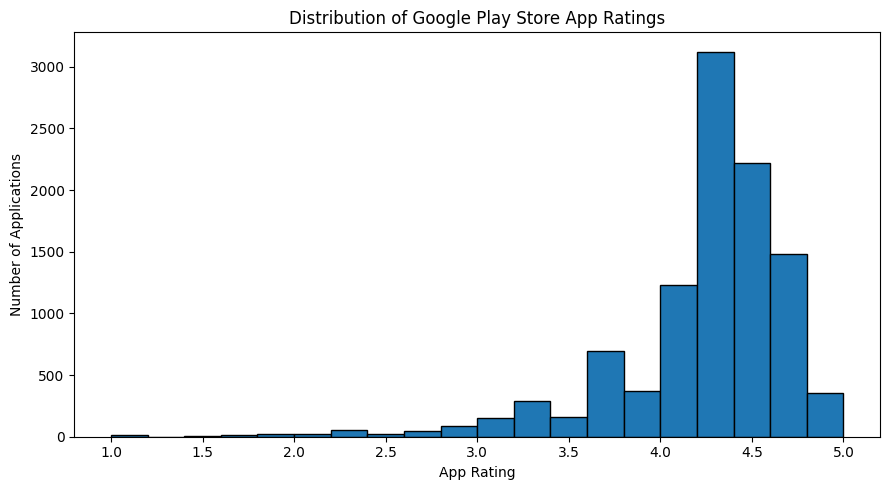

In [25]:
# 1. Histogram: app rating distribution.
plt.figure(figsize=(9, 5))
plt.hist(df_clean["rating"], bins=20, edgecolor="black")
plt.title("Distribution of Google Play Store App Ratings")
plt.xlabel("App Rating")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()

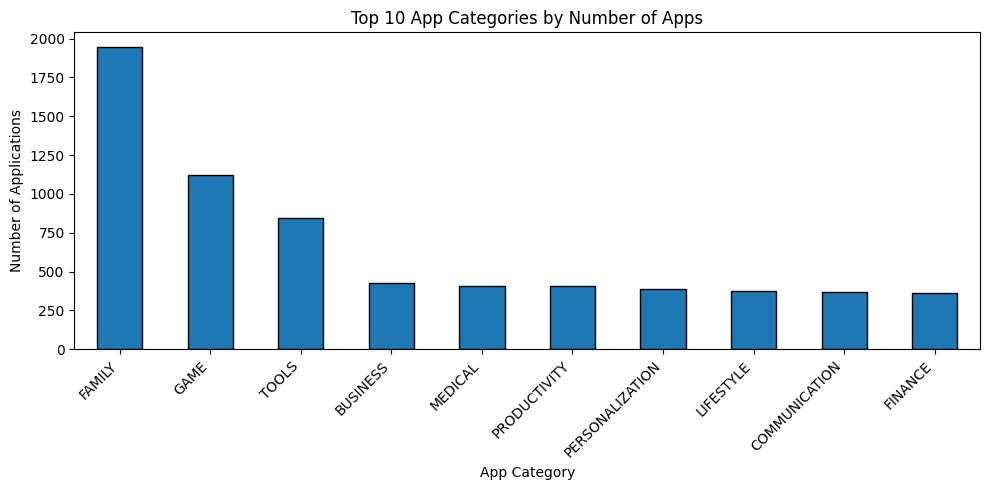

In [21]:
# 2. Bar chart: top 10 categories by app count.
category_counts = df_clean["category"].value_counts().head(10)
plt.figure(figsize=(10, 5))
category_counts.plot(kind="bar", edgecolor="black")
plt.title("Top 10 App Categories by Number of Apps")
plt.xlabel("App Category")
plt.ylabel("Number of Applications")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

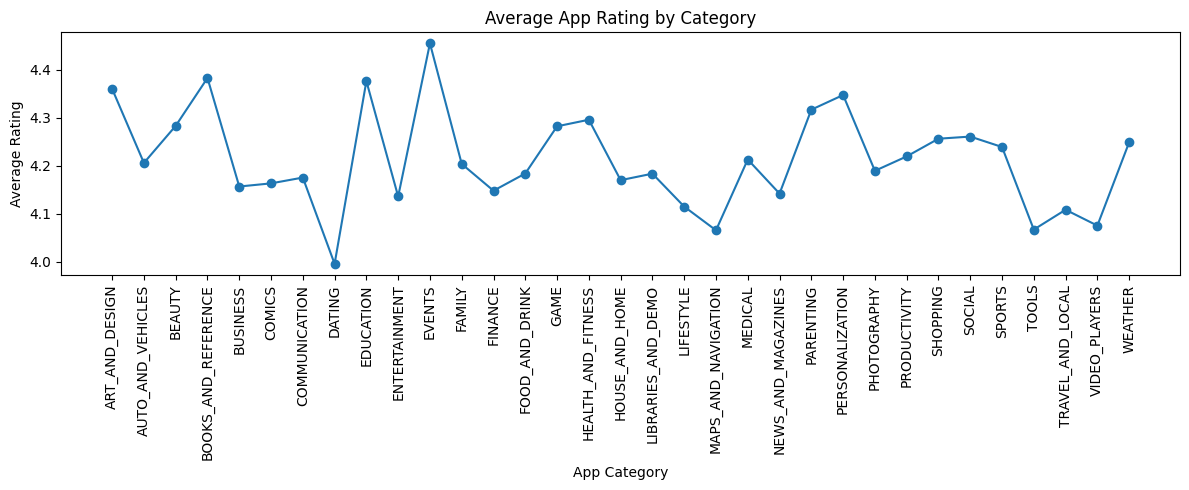

In [26]:
# 3. Line chart: average rating by category.
average_rating_by_category = (
    df_clean.groupby("category")["rating"].mean().sort_index()
)
plt.figure(figsize=(12, 5))
plt.plot(
    average_rating_by_category.index,
    average_rating_by_category.values,
    marker="o"
)
plt.title("Average App Rating by Category")
plt.xlabel("App Category")
plt.ylabel("Average Rating")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

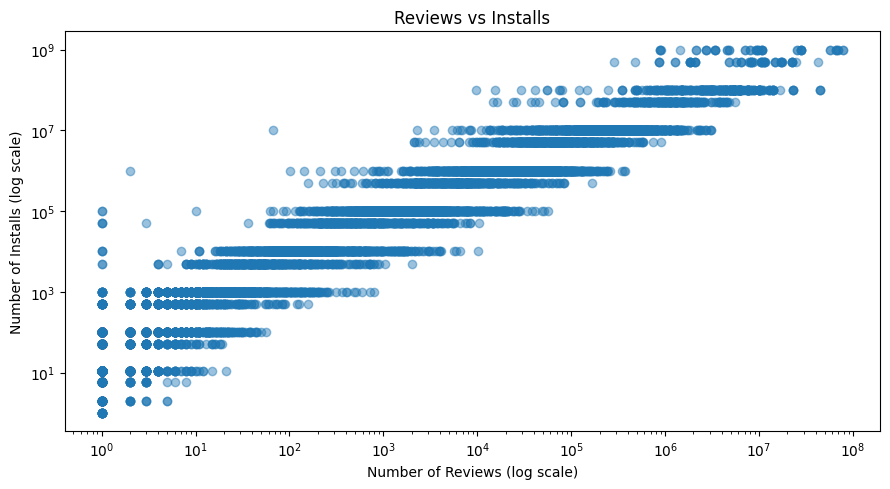

In [23]:
# 4. Scatter plot: reviews versus installs.
# Log scales make highly skewed values easier to inspect.
plt.figure(figsize=(9, 5))
plt.scatter(
    df_clean["reviews"] + 1,
    df_clean["installs_numeric"] + 1,
    alpha=0.45
)
plt.xscale("log")
plt.yscale("log")
plt.title("Reviews vs Installs")
plt.xlabel("Number of Reviews (log scale)")
plt.ylabel("Number of Installs (log scale)")
plt.tight_layout()
plt.show()

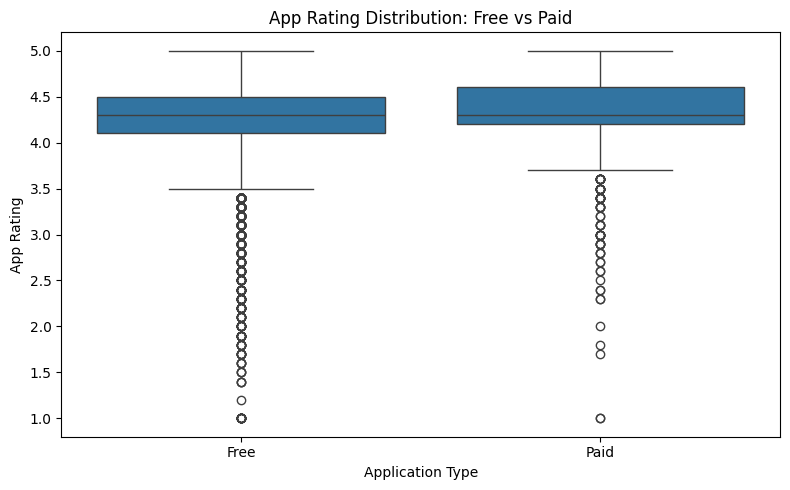

In [27]:
# 5. Box plot: app ratings by free/paid type.
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="type", y="rating")
plt.title("App Rating Distribution: Free vs Paid")
plt.xlabel("Application Type")
plt.ylabel("App Rating")
plt.tight_layout()
plt.show()

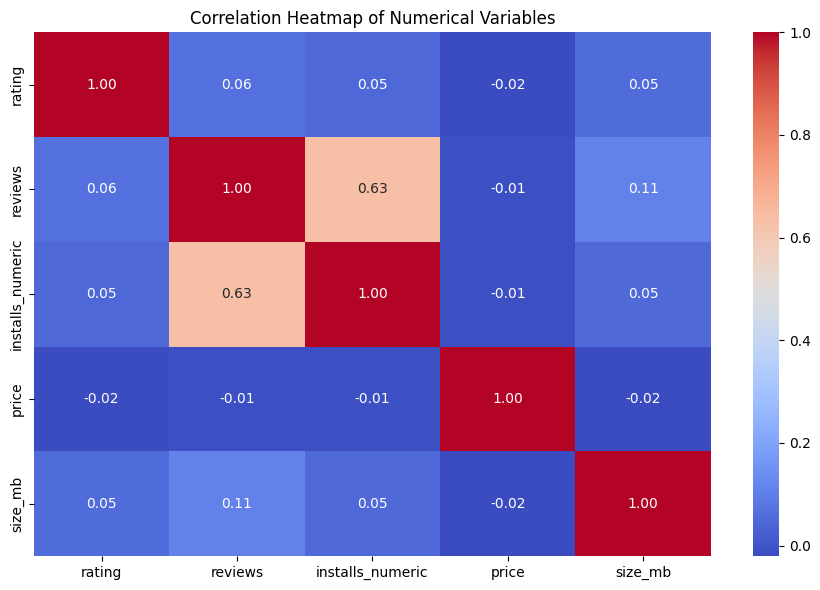

In [28]:
# 6. Correlation heatmap.
plt.figure(figsize=(9, 6))
sns.heatmap(
    df_clean[correlation_cols].corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

#### Interactive Visualization Using Plotly

Plotly charts support hover details, zooming, panning, and interactive exploration.

In [29]:
import plotly.express as px

# 1. Interactive histogram.
fig = px.histogram(
    df_clean,
    x="rating",
    nbins=20,
    title="Interactive Distribution of App Ratings",
    labels={"rating": "App Rating", "count": "Number of Applications"}
)
fig.show(renderer='browser')

In [31]:
# 2. Interactive scatter plot.
fig = px.scatter(
    df_clean,
    x="reviews",
    y="installs_numeric",
    color="type",
    hover_name="app",
    hover_data=["category", "rating", "price"],
    title="Reviews vs Installs",
    labels={
        "reviews": "Number of Reviews",
        "installs_numeric": "Number of Installs",
        "type": "App Type"
    },
    log_x=True,
    log_y=True
)
fig.show(renderer='browser')

In [31]:
# 3. Interactive bar chart: total installs by category.
category_installs = (
    df_clean.groupby("category", as_index=False)
    .agg(total_installs=("installs_numeric", "sum"))
    .sort_values("total_installs", ascending=False)
)

fig = px.bar(
    category_installs,
    x="category",
    y="total_installs",
    color="total_installs",
    title="Total Installs by App Category",
    labels={
        "category": "App Category",
        "total_installs": "Total Installs"
    },
    hover_data={"total_installs": ":,"}
)
fig.update_layout(xaxis_tickangle=-45)
fig.show(renderer='browser')

## Step 8 – Feature Engineering

Create meaningful features, extract date components, encode categorical columns, and scale numerical columns. The transformed data is prepared separately so the readable cleaned dataset remains unchanged.

In [32]:
# Create five new features.
def popularity_level(installs):
    if installs >= 10_000_000:
        return "High"
    elif installs >= 100_000:
        return "Medium"
    return "Low"

df_features = df_clean.copy()
df_features["popularity_level"] = df_features["installs_numeric"].apply(popularity_level)

# Reviews per install is an approximate engagement ratio.
df_features["reviews_per_install"] = (
    df_features["reviews"] /
    df_features["installs_numeric"].replace(0, np.nan)
).fillna(0)

def size_category(size):
    if pd.isna(size):
        return "Unknown"
    if size < 20:
        return "Small"
    elif size < 50:
        return "Medium"
    return "Large"

df_features["size_category"] = df_features["size_mb"].apply(size_category)

# Date/time feature extraction.
df_features["update_year"] = df_features["last_updated"].dt.year
df_features["update_month"] = df_features["last_updated"].dt.month

display(df_features[[
    "app", "popularity_level", "reviews_per_install",
    "size_category", "update_year", "update_month"
]].head())

,app,popularity_level,reviews_per_install,size_category,update_year,update_month
0,Photo Editor & Candy Camera & Grid & ScrapBook,Low,0.015900,Small,2018,1
1,Coloring book moana,Medium,0.001934,Small,2018,1
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",Medium,0.017502,Small,2018,8
3,Sketch - Draw & Paint,High,0.004313,Medium,2018,6
4,Pixel Draw - Number Art Coloring Book,Medium,0.009670,Small,2018,6


In [33]:
# Purpose of engineered features.
feature_purposes = pd.DataFrame({
    "Feature": [
        "popularity_level", "reviews_per_install",
        "size_category", "update_year", "update_month"
    ],
    "Purpose": [
        "Groups apps by approximate installation volume.",
        "Measures reviews relative to installation count.",
        "Groups apps by their size in MB.",
        "Extracts the year of the latest update.",
        "Extracts the month of the latest update."
    ]
})
display(feature_purposes)

,Feature,Purpose
0,popularity_level,Groups apps by approximate installation volume.
1,reviews_per_install,Measures reviews relative to installation count.
2,size_category,Groups apps by their size in MB.
3,update_year,Extracts the year of the latest update.
4,update_month,Extracts the month of the latest update.


In [33]:
# Label encode selected categorical features.
from sklearn.preprocessing import LabelEncoder

df_encoded = df_features.copy()
categorical_to_encode = [
    "category", "type", "content_rating", "genres",
    "popularity_level", "size_category"
]

label_encoders = {}
for col in categorical_to_encode:
    encoder = LabelEncoder()
    df_encoded[col] = encoder.fit_transform(df_encoded[col].astype(str))
    label_encoders[col] = encoder

print("Categorical encoding completed.")
display(df_encoded[categorical_to_encode].head())

Categorical encoding completed.


,category,type,content_rating,genres,popularity_level,size_category
0,0,0,1,9,1,2
1,0,0,1,12,2,2
2,0,0,1,9,2,2
3,0,0,4,9,0,1
4,0,0,1,11,2,2


In [35]:
# Standardize selected numerical columns.
from sklearn.preprocessing import StandardScaler

scaling_columns = [
    "rating", "reviews", "installs_numeric",
    "price", "size_mb", "reviews_per_install"
]

df_scaled = df_encoded.copy()
scaler = StandardScaler()
df_scaled[scaling_columns] = scaler.fit_transform(df_scaled[scaling_columns])

print("Numerical scaling completed.")
display(df_scaled[scaling_columns].head())

Numerical scaling completed.


,rating,reviews,installs_numeric,price,size_mb,reviews_per_install
0,-0.210409,-0.150463,-0.176328,-0.063325,-0.050733,-0.228926
1,-0.621637,-0.150163,-0.170221,-0.063325,-0.288613,-0.372577
2,1.023276,-0.118071,-0.114136,-0.063325,-0.540766,-0.212448
3,0.612048,-0.070554,0.446712,-0.063325,0.234724,-0.348109
4,0.200820,-0.150163,-0.175206,-0.063325,-0.821465,-0.293007


#### Analysis and Conclusion

Summarize findings, provide recommendations, and document dataset limitations.

In [34]:
# Generate a concise final analysis from the cleaned data.
total_apps = len(df_clean)
mean_rating = df_clean["rating"].mean()
most_installed_category = (
    df_clean.groupby("category")["installs_numeric"].sum().idxmax()
)
highest_avg_rating_category = (
    df_clean.groupby("category")["rating"].mean().idxmax()
)
free_count = int(df_clean["type"].eq("Free").sum())
paid_count = int(df_clean["type"].eq("Paid").sum())
most_common_content = df_clean["content_rating"].mode().iloc[0]

print("GOOGLE PLAY STORE – FINAL ANALYSIS")
print("----------------------------------")
print(f"Total app records after cleaning: {total_apps:,}")
print(f"Average app rating after imputation: {mean_rating:.2f}")
print(f"Category with highest total installs: {most_installed_category}")
print(f"Category with highest average rating: {highest_avg_rating_category}")
print(f"Free apps: {free_count:,}")
print(f"Paid apps: {paid_count:,}")
print(f"Most common content rating: {most_common_content}")
print(f"Remaining missing cells: {df_clean.isna().sum().sum()}")
print(f"Remaining duplicate rows: {df_clean.duplicated().sum()}")

GOOGLE PLAY STORE – FINAL ANALYSIS
----------------------------------
Total app records after cleaning: 10,357
Average app rating after imputation: 4.20
Category with highest total installs: GAME
Category with highest average rating: EVENTS
Free apps: 9,592
Paid apps: 765
Most common content rating: Everyone
Remaining missing cells: 0
Remaining duplicate rows: 0


#### Conclusions and recommendations

1. Compare categories using both total installations and average ratings; these measure different aspects of app performance.
2. Developers can monitor reviews and installation trends to understand engagement, while remembering that correlation does not prove causation.
3. Free and paid applications should be evaluated separately because their pricing models and installation patterns may differ.
4. App developers should consider app size, update frequency, and content rating when planning product improvements.

#### Limitations

1. The dataset is a historical snapshot and may not represent current Play Store rankings or app performance.
2. Installation counts are shown in rounded/range-like values (for example, `1,000+`), not exact counts.
3. Missing ratings were imputed using category medians, which can affect summary statistics and visualizations.
4. The dataset does not include individual review text, user demographics, or detailed user behavior.
5. Correlation indicates association, not causation.
6. Some statistical outliers may be genuine high-performing apps and were therefore not automatically removed.